# Cellphone Price Range Prediction

## Project Overview
This project focuses on analyzing mobile phone specifications and predicting the **price range** of a mobile phone using Machine Learning classification techniques.

## Problem Statement
A mobile phone company wants to estimate the appropriate price range for its newly developed mobile phones. Instead of predicting the exact selling price, the objective is to classify each mobile phone into one of four price categories based on its specifications.

## Dataset
The dataset contains information about different mobile phone specifications, including:
- Battery power
- RAM
- Internal memory
- Camera specifications
- Pixel resolution
- Processor cores
- Screen dimensions
- Mobile weight
- 3G/4G availability
- Wi-Fi and Bluetooth
- Touch screen
- Dual SIM support
- Talk time

## Target Variable
The target variable is **price_range**, which contains four categories:
- **0 – Low Cost**
- **1 – Medium Cost**
- **2 – High Cost**
- **3 – Very High Cost**

## Project Objectives
1. Perform data analysis and understand the mobile phone dataset.
2. Explore relationships between mobile specifications and price range.
3. Preprocess the data for Machine Learning.
4. Train and evaluate multiple classification models.
5. Compare model performance and select the best model for production.
6. Identify the most important features influencing the price range.
7. Predict the price range of a new mobile phone based on its specifications.
8. Analyze how the model can help the company make better pricing and business decisions.

## Import Basic libraries

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

In [2]:
df = pd.read_csv("datasets_11167_15520_train.csv")

## Basic checks

In [3]:
df.head()

,battery_power,blue,clock_speed,dual_sim,fc,four_g,int_memory,m_dep,mobile_wt,n_cores,...,px_height,px_width,ram,sc_h,sc_w,talk_time,three_g,touch_screen,wifi,price_range
0,842,0,2.2,0,1,0,7,0.6,188,2,...,20,756,2549,9,7,19,0,0,1,1
1,1021,1,0.5,1,0,1,53,0.7,136,3,...,905,1988,2631,17,3,7,1,1,0,2
2,563,1,0.5,1,2,1,41,0.9,145,5,...,1263,1716,2603,11,2,9,1,1,0,2
3,615,1,2.5,0,0,0,10,0.8,131,6,...,1216,1786,2769,16,8,11,1,0,0,2
4,1821,1,1.2,0,13,1,44,0.6,141,2,...,1208,1212,1411,8,2,15,1,1,0,1


In [4]:
df.shape

(2000, 21)

In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2000 entries, 0 to 1999
Data columns (total 21 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   battery_power  2000 non-null   int64  
 1   blue           2000 non-null   int64  
 2   clock_speed    2000 non-null   float64
 3   dual_sim       2000 non-null   int64  
 4   fc             2000 non-null   int64  
 5   four_g         2000 non-null   int64  
 6   int_memory     2000 non-null   int64  
 7   m_dep          2000 non-null   float64
 8   mobile_wt      2000 non-null   int64  
 9   n_cores        2000 non-null   int64  
 10  pc             2000 non-null   int64  
 11  px_height      2000 non-null   int64  
 12  px_width       2000 non-null   int64  
 13  ram            2000 non-null   int64  
 14  sc_h           2000 non-null   int64  
 15  sc_w           2000 non-null   int64  
 16  talk_time      2000 non-null   int64  
 17  three_g        2000 non-null   int64  
 18  touch_sc

In [7]:
df.describe()

,battery_power,blue,clock_speed,dual_sim,fc,four_g,int_memory,m_dep,mobile_wt,n_cores,...,px_height,px_width,ram,sc_h,sc_w,talk_time,three_g,touch_screen,wifi,price_range
count,2000.000000,2000.0000,2000.000000,2000.000000,2000.000000,2000.000000,2000.000000,2000.000000,2000.000000,2000.000000,...,2000.000000,2000.000000,2000.000000,2000.000000,2000.000000,2000.000000,2000.000000,2000.000000,2000.000000,2000.000000
mean,1238.518500,0.4950,1.522250,0.509500,4.309500,0.521500,32.046500,0.501750,140.249000,4.520500,...,645.108000,1251.515500,2124.213000,12.306500,5.767000,11.011000,0.761500,0.503000,0.507000,1.500000
std,439.418206,0.5001,0.816004,0.500035,4.341444,0.499662,18.145715,0.288416,35.399655,2.287837,...,443.780811,432.199447,1084.732044,4.213245,4.356398,5.463955,0.426273,0.500116,0.500076,1.118314
min,501.000000,0.0000,0.500000,0.000000,0.000000,0.000000,2.000000,0.100000,80.000000,1.000000,...,0.000000,500.000000,256.000000,5.000000,0.000000,2.000000,0.000000,0.000000,0.000000,0.000000
25%,851.750000,0.0000,0.700000,0.000000,1.000000,0.000000,16.000000,0.200000,109.000000,3.000000,...,282.750000,874.750000,1207.500000,9.000000,2.000000,6.000000,1.000000,0.000000,0.000000,0.750000
50%,1226.000000,0.0000,1.500000,1.000000,3.000000,1.000000,32.000000,0.500000,141.000000,4.000000,...,564.000000,1247.000000,2146.500000,12.000000,5.000000,11.000000,1.000000,1.000000,1.000000,1.500000
75%,1615.250000,1.0000,2.200000,1.000000,7.000000,1.000000,48.000000,0.800000,170.000000,7.000000,...,947.250000,1633.000000,3064.500000,16.000000,9.000000,16.000000,1.000000,1.000000,1.000000,2.250000
max,1998.000000,1.0000,3.000000,1.000000,19.000000,1.000000,64.000000,1.000000,200.000000,8.000000,...,1960.000000,1998.000000,3998.000000,19.000000,18.000000,20.000000,1.000000,1.000000,1.000000,3.000000


In [8]:
df.isnull().sum()

battery_power    0
blue             0
clock_speed      0
dual_sim         0
fc               0
four_g           0
int_memory       0
m_dep            0
mobile_wt        0
n_cores          0
pc               0
px_height        0
px_width         0
ram              0
sc_h             0
sc_w             0
talk_time        0
three_g          0
touch_screen     0
wifi             0
price_range      0
dtype: int64

In [9]:
df['price_range'].value_counts()

price_range
1    500
2    500
3    500
0    500
Name: count, dtype: int64

In [10]:
df.duplicated().sum()

np.int64(0)

In [11]:
df['price_range'].unique()

array([1, 2, 3, 0])

## EDA

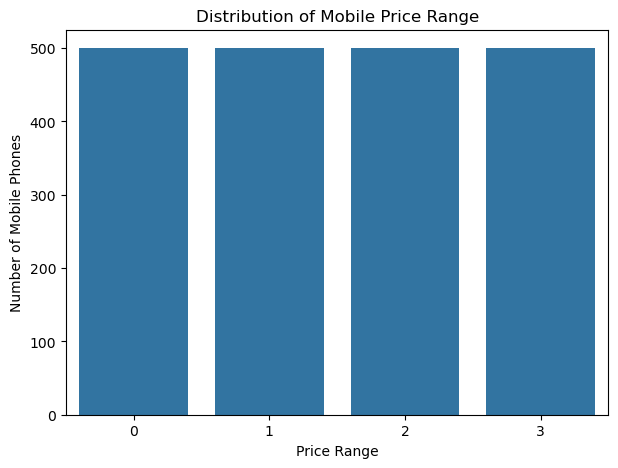

In [13]:
plt.figure(figsize=(7, 5))
sns.countplot(x='price_range', data=df)

plt.title('Distribution of Mobile Price Range')
plt.xlabel('Price Range')
plt.ylabel('Number of Mobile Phones')
plt.show()

In [14]:
df['price_range'].value_counts().sort_index()

price_range
0    500
1    500
2    500
3    500
Name: count, dtype: int64

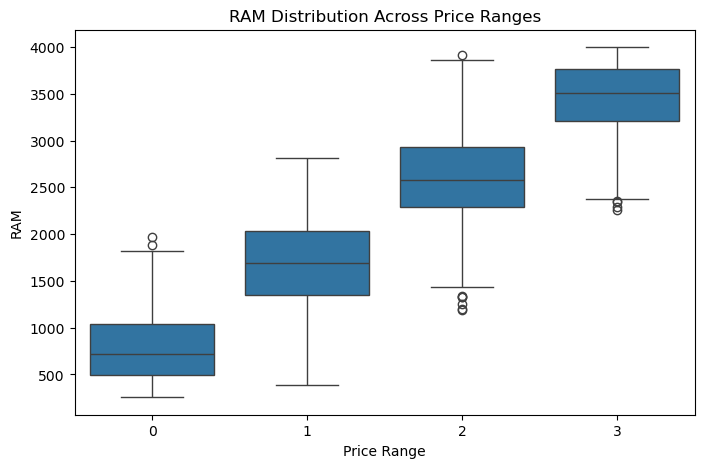

In [16]:
# RAM vs Price range

plt.figure(figsize=(8, 5))
sns.boxplot(x='price_range', y='ram', data=df)

plt.title('RAM Distribution Across Price Ranges')
plt.xlabel('Price Range')
plt.ylabel('RAM')
plt.show()

In [17]:
df.groupby('price_range')['ram'].mean()

price_range
0     785.314
1    1679.490
2    2582.816
3    3449.232
Name: ram, dtype: float64

### RAM vs Price Range

The analysis shows a strong relationship between RAM and mobile phone price range. The average RAM increases consistently from approximately 785 MB for low-cost phones to 3,449 MB for very high-cost phones. This indicates that RAM is likely to be an important feature for predicting the price range of a mobile phone.

In [18]:
df.groupby('price_range')['battery_power'].mean()

price_range
0    1116.902
1    1228.868
2    1228.320
3    1379.984
Name: battery_power, dtype: float64

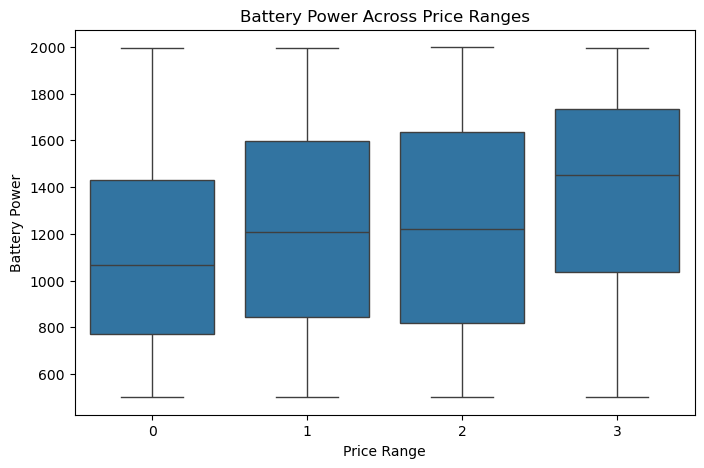

In [20]:
# Battery Power vs Price range

plt.figure(figsize=(8, 5))
sns.boxplot(x='price_range', y='battery_power', data=df)

plt.title('Battery Power Across Price Ranges')
plt.xlabel('Price Range')
plt.ylabel('Battery Power')

plt.show()

### Battery Power vs Price Range

The average battery power generally increases with the price range. Low-cost phones have an average battery power of approximately 1117, while very high-cost phones have an average of approximately 1380. However, the difference between the middle price ranges is very small, indicating that battery power has a weaker relationship with price range compared to RAM.

In [22]:
# Pixel Resolution vs Price range

df.groupby('price_range')[['px_height', 'px_width']].mean()

,px_height,px_width
price_range,,
0,536.408,1150.270
1,666.892,1251.908
2,632.284,1234.046
3,744.848,1369.838


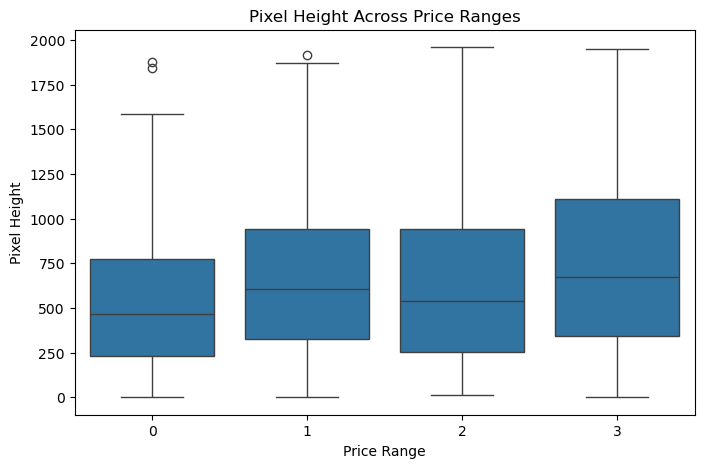

In [23]:
plt.figure(figsize=(8, 5))
sns.boxplot(x='price_range', y='px_height', data=df)

plt.title('Pixel Height Across Price Ranges')
plt.xlabel('Price Range')
plt.ylabel('Pixel Height')

plt.show()

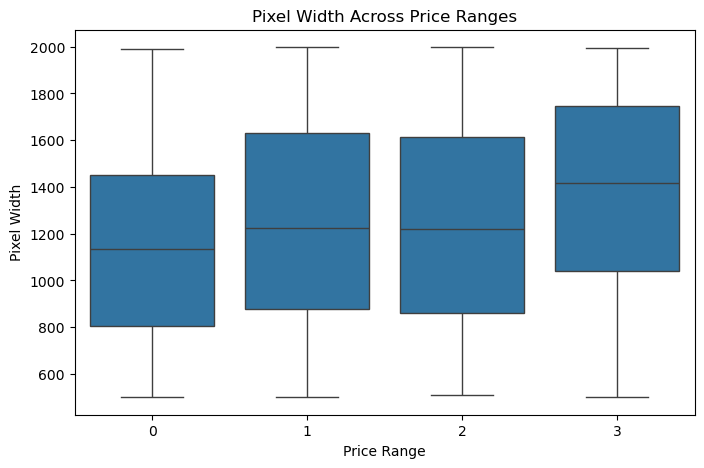

In [24]:
plt.figure(figsize=(8, 5))

sns.boxplot(x='price_range', y='px_width', data=df)

plt.title('Pixel Width Across Price Ranges')
plt.xlabel('Price Range')
plt.ylabel('Pixel Width')

plt.show()

### Pixel Resolution vs Price Range

Pixel resolution shows a general relationship with mobile phone price range. The average pixel width increases from approximately 1150 for low-cost phones to 1370 for very high-cost phones. Pixel height also generally increases with price range, although there is a slight variation in the middle categories. This suggests that display resolution can contribute to price range prediction, but its influence may be lower than features such as RAM.

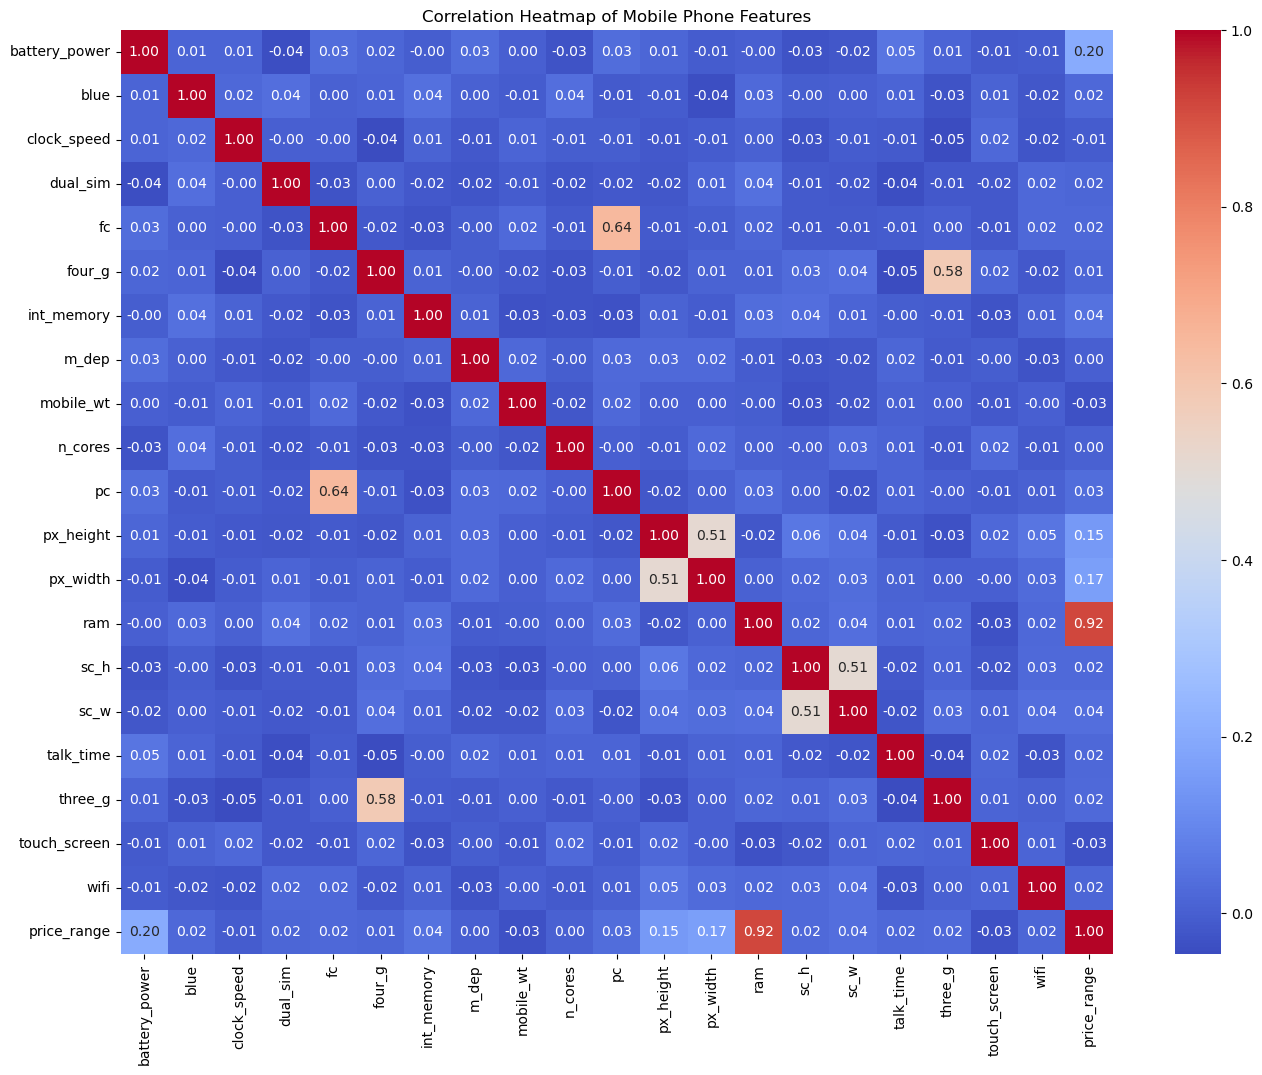

In [25]:
# Correraltion Heatmap

plt.figure(figsize=(16, 12))
corr = df.corr()
sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm')
plt.title('Correlation Heatmap of Mobile Phone Features')
plt.show()

In [26]:
df.corr()['price_range'].sort_values(ascending=False)

price_range      1.000000
ram              0.917046
battery_power    0.200723
px_width         0.165818
px_height        0.148858
int_memory       0.044435
sc_w             0.038711
pc               0.033599
three_g          0.023611
sc_h             0.022986
fc               0.021998
talk_time        0.021859
blue             0.020573
wifi             0.018785
dual_sim         0.017444
four_g           0.014772
n_cores          0.004399
m_dep            0.000853
clock_speed     -0.006606
mobile_wt       -0.030302
touch_screen    -0.030411
Name: price_range, dtype: float64

### Correlation Analysis

The correlation analysis shows that RAM has the strongest positive relationship with price range, with a correlation coefficient of 0.917. This indicates that RAM is a highly influential feature for distinguishing between different mobile price categories.

Battery power, pixel width, and pixel height show weaker positive relationships with price range. Most of the remaining features have correlations close to zero, indicating weak linear relationships with the target variable.

However, low correlation does not necessarily mean that a feature is unimportant, as machine learning models may identify nonlinear relationships and interactions between features.

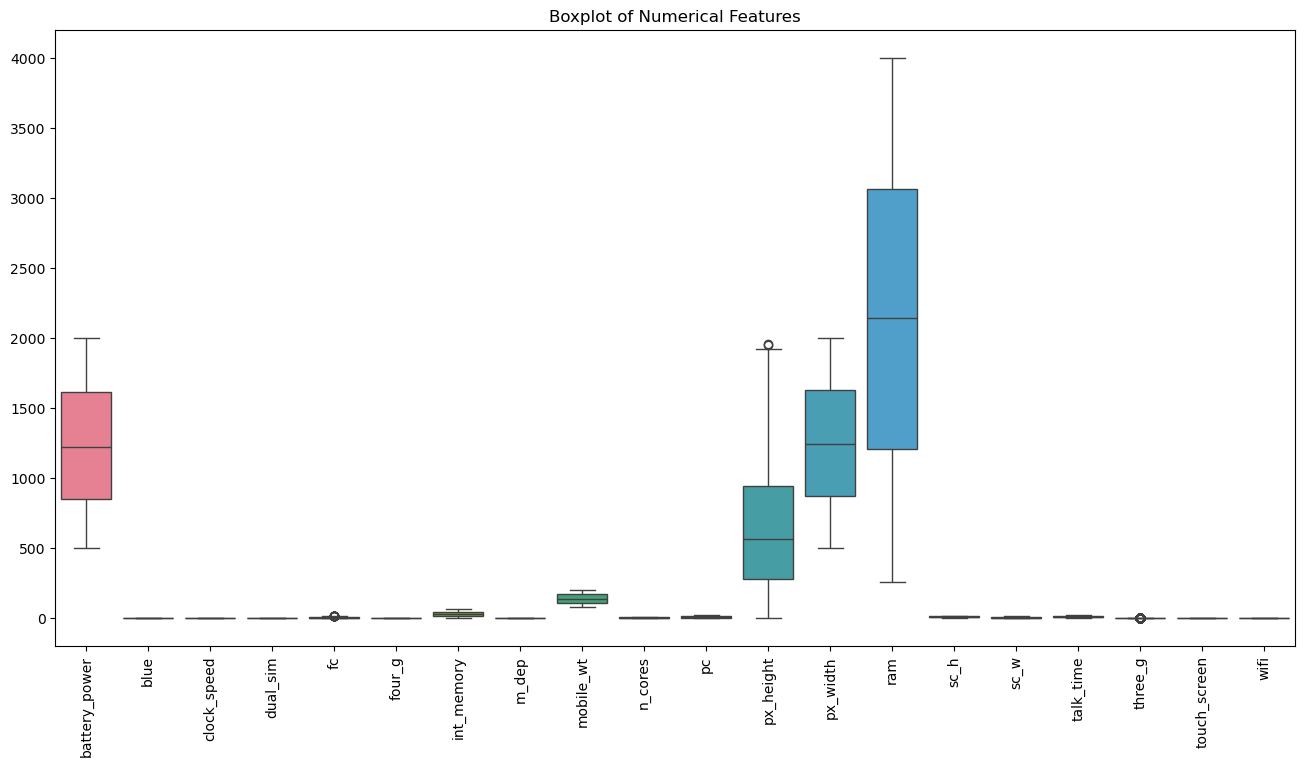

In [27]:
plt.figure(figsize=(16, 8))
sns.boxplot(data=df.drop(columns='price_range'))
plt.xticks(rotation=90)
plt.title('Boxplot of Numerical Features')
plt.show()

## Data Preprocessing

In [28]:
X = df.drop('price_range', axis=1)
y = df['price_range']

In [29]:
print("Features shape:", X.shape)
print("Target shape:", y.shape)

Features shape: (2000, 20)
Target shape: (2000,)


In [30]:
# Train-Test-Split

from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

In [31]:
print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (1600, 20)
Testing data: (400, 20)


In [32]:
# Feature Scaling

from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [33]:
# Logistic Regression

from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

lr_model = LogisticRegression(max_iter=1000, random_state=42)

lr_model.fit(X_train_scaled, y_train)

y_pred_lr = lr_model.predict(X_test_scaled)

lr_accuracy = accuracy_score(y_test, y_pred_lr)

print("Logistic Regression Accuracy:", lr_accuracy)
print("\nClassification Report:")
print(classification_report(y_test, y_pred_lr))

Logistic Regression Accuracy: 0.965

Classification Report:
              precision    recall  f1-score   support

           0       0.99      0.98      0.98       100
           1       0.96      0.96      0.96       100
           2       0.95      0.94      0.94       100
           3       0.96      0.98      0.97       100

    accuracy                           0.96       400
   macro avg       0.97      0.96      0.96       400
weighted avg       0.97      0.96      0.96       400



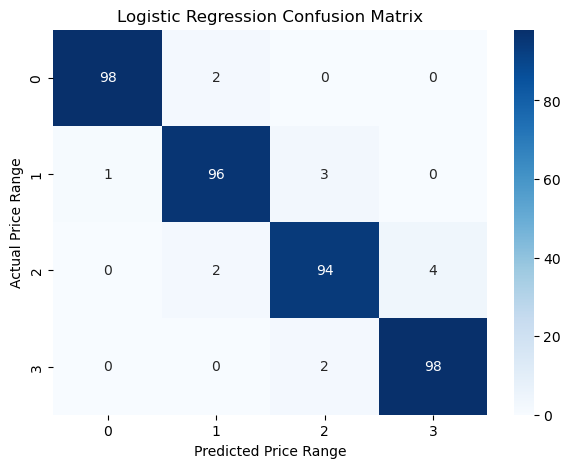

In [34]:
cm_lr = confusion_matrix(y_test, y_pred_lr)

plt.figure(figsize=(7, 5))
sns.heatmap(
    cm_lr,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=[0, 1, 2, 3],
    yticklabels=[0, 1, 2, 3]
)

plt.title('Logistic Regression Confusion Matrix')
plt.xlabel('Predicted Price Range')
plt.ylabel('Actual Price Range')
plt.show()

### Logistic Regression Results

Logistic Regression achieved an accuracy of 96.5% on the test dataset. The model performed consistently well across all four price ranges, with F1-scores ranging from 0.94 to 0.98. The macro-average F1-score was 0.96, indicating strong and balanced classification performance across all price categories.

Price Range 0 achieved the highest F1-score of 0.98, while Price Range 2 had the lowest F1-score of 0.94. Overall, Logistic Regression provides a strong baseline model for cellphone price range prediction.

In [35]:
# K-Nearest Neighbour(KNN)

from sklearn.neighbors import KNeighborsClassifier

knn_model = KNeighborsClassifier(n_neighbors=5)

knn_model.fit(X_train_scaled, y_train)

y_pred_knn = knn_model.predict(X_test_scaled)

knn_accuracy = accuracy_score(y_test, y_pred_knn)

print("KNN Accuracy:", knn_accuracy)
print("\nClassification Report:")
print(classification_report(y_test, y_pred_knn))

KNN Accuracy: 0.5

Classification Report:
              precision    recall  f1-score   support

           0       0.65      0.70      0.67       100
           1       0.33      0.38      0.35       100
           2       0.39      0.41      0.40       100
           3       0.72      0.51      0.60       100

    accuracy                           0.50       400
   macro avg       0.52      0.50      0.51       400
weighted avg       0.52      0.50      0.51       400



### KNN Results

K-Nearest Neighbors achieved an accuracy of only 50.0%, with a macro-average F1-score of 0.51. The model performed considerably worse than Logistic Regression. Price Range 0 had the highest F1-score of 0.67, while Price Range 2 had the lowest at 0.40.

The poor performance suggests that distance-based classification with the selected KNN configuration is not well suited to this dataset. Therefore, KNN is unlikely to be the preferred production model based on its current performance.

In [36]:
# Decision Tree

from sklearn.tree import DecisionTreeClassifier

dt_model = DecisionTreeClassifier(
    random_state=42,
    max_depth=None
)

dt_model.fit(X_train, y_train)

y_pred_dt = dt_model.predict(X_test)

dt_accuracy = accuracy_score(y_test, y_pred_dt)

print("Decision Tree Accuracy:", dt_accuracy)
print("\nClassification Report:")
print(classification_report(y_test, y_pred_dt))

Decision Tree Accuracy: 0.83

Classification Report:
              precision    recall  f1-score   support

           0       0.88      0.92      0.90       100
           1       0.78      0.74      0.76       100
           2       0.75      0.80      0.77       100
           3       0.92      0.86      0.89       100

    accuracy                           0.83       400
   macro avg       0.83      0.83      0.83       400
weighted avg       0.83      0.83      0.83       400



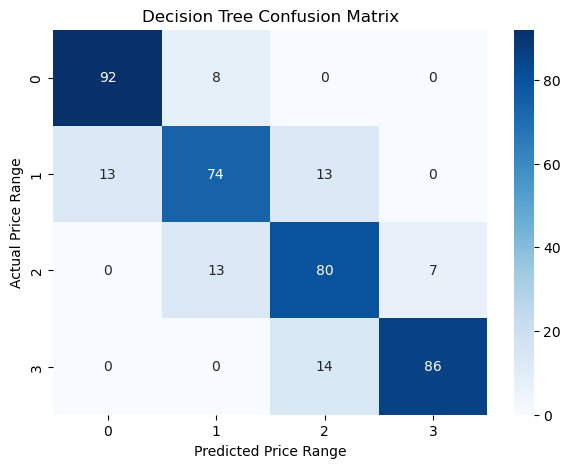

In [37]:
cm_dt = confusion_matrix(y_test, y_pred_dt)

plt.figure(figsize=(7, 5))
sns.heatmap(
    cm_dt,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=[0, 1, 2, 3],
    yticklabels=[0, 1, 2, 3]
)

plt.title('Decision Tree Confusion Matrix')
plt.xlabel('Predicted Price Range')
plt.ylabel('Actual Price Range')
plt.show()

### Decision Tree Results

The Decision Tree achieved an accuracy of 83.0% and a macro-average F1-score of 0.83. The model performed best on Price Range 0 and Price Range 3, with F1-scores of 0.90 and 0.89 respectively. Price Ranges 1 and 2 were more difficult to classify, with F1-scores of 0.76 and 0.77.

Although the Decision Tree performs considerably better than KNN, its performance is still lower than Logistic Regression. Therefore, Logistic Regression remains the best-performing model so far.

In [38]:
# Random Forest

from sklearn.ensemble import RandomForestClassifier

rf_model = RandomForestClassifier(
    n_estimators=100,
    random_state=42
)

rf_model.fit(X_train, y_train)

y_pred_rf = rf_model.predict(X_test)

rf_accuracy = accuracy_score(y_test, y_pred_rf)

print("Random Forest Accuracy:", rf_accuracy)
print("\nClassification Report:")
print(classification_report(y_test, y_pred_rf))

Random Forest Accuracy: 0.88

Classification Report:
              precision    recall  f1-score   support

           0       0.95      0.96      0.96       100
           1       0.82      0.83      0.83       100
           2       0.81      0.80      0.80       100
           3       0.94      0.93      0.93       100

    accuracy                           0.88       400
   macro avg       0.88      0.88      0.88       400
weighted avg       0.88      0.88      0.88       400



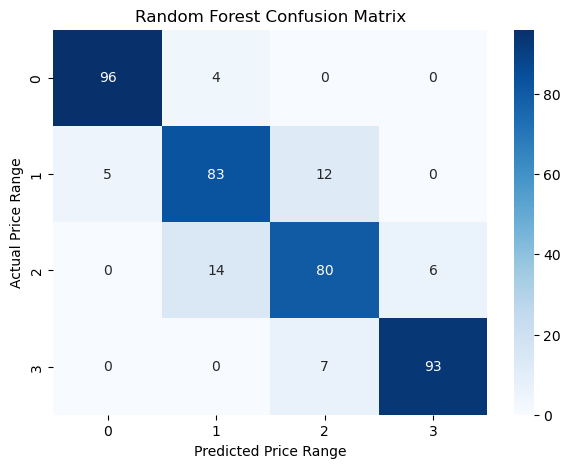

In [39]:
cm_rf = confusion_matrix(y_test, y_pred_rf)

plt.figure(figsize=(7, 5))
sns.heatmap(
    cm_rf,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=[0, 1, 2, 3],
    yticklabels=[0, 1, 2, 3]
)

plt.title('Random Forest Confusion Matrix')
plt.xlabel('Predicted Price Range')
plt.ylabel('Actual Price Range')
plt.show()

### Random Forest Results

The Random Forest model achieved an accuracy of 88.0% and a macro-average F1-score of 0.88. It performed particularly well for Price Range 0 and Price Range 3, achieving F1-scores of 0.96 and 0.93 respectively.

The model performed less effectively for Price Ranges 1 and 2, with F1-scores of 0.83 and 0.80. Random Forest significantly outperformed the single Decision Tree and KNN models, but its performance is still below Logistic Regression.

In [40]:
# SVM

from sklearn.svm import SVC

svm_model = SVC(kernel='rbf', random_state=42)

svm_model.fit(X_train_scaled, y_train)

y_pred_svm = svm_model.predict(X_test_scaled)

svm_accuracy = accuracy_score(y_test, y_pred_svm)

print("SVM Accuracy:", svm_accuracy)
print("\nClassification Report:")
print(classification_report(y_test, y_pred_svm))

SVM Accuracy: 0.895

Classification Report:
              precision    recall  f1-score   support

           0       0.96      0.94      0.95       100
           1       0.87      0.87      0.87       100
           2       0.82      0.87      0.84       100
           3       0.94      0.90      0.92       100

    accuracy                           0.90       400
   macro avg       0.90      0.90      0.90       400
weighted avg       0.90      0.90      0.90       400



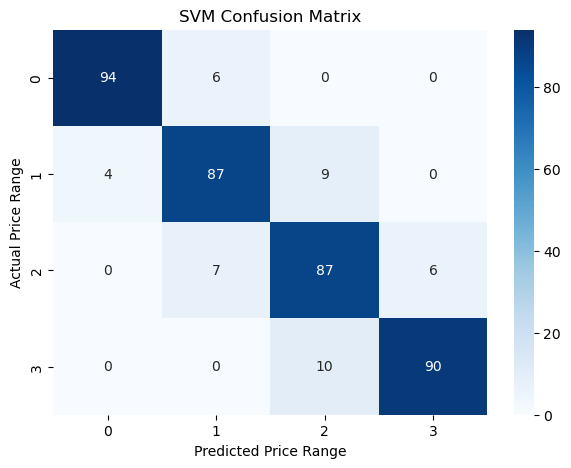

In [41]:
cm_svm = confusion_matrix(y_test, y_pred_svm)

plt.figure(figsize=(7, 5))
sns.heatmap(
    cm_svm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=[0, 1, 2, 3],
    yticklabels=[0, 1, 2, 3]
)

plt.title('SVM Confusion Matrix')
plt.xlabel('Predicted Price Range')
plt.ylabel('Actual Price Range')
plt.show()

### SVM Results

The Support Vector Machine achieved an accuracy of 89.5% and a macro-average F1-score of 0.90. The model performed well across all four price categories, with F1-scores ranging from 0.84 to 0.95.

SVM performed better than Random Forest, Decision Tree, and KNN, but it was still less accurate than Logistic Regression. Therefore, Logistic Regression remains the best-performing model among the five evaluated models.

In [42]:
# Model Comparison

model_comparison = pd.DataFrame({
    'Model': [
        'Logistic Regression',
        'KNN',
        'Decision Tree',
        'Random Forest',
        'SVM'
    ],
    'Accuracy': [
        lr_accuracy,
        knn_accuracy,
        dt_accuracy,
        rf_accuracy,
        svm_accuracy
    ],
    'Macro F1': [
        0.96,
        0.51,
        0.83,
        0.88,
        0.90
    ]
})

model_comparison.sort_values(
    by='Accuracy',
    ascending=False
).reset_index(drop=True)

,Model,Accuracy,Macro F1
0,Logistic Regression,0.965,0.96
1,SVM,0.895,0.90
2,Random Forest,0.880,0.88
3,Decision Tree,0.830,0.83
4,KNN,0.500,0.51


### Model Comparison Conclusion

Among all the classification models tested, Logistic Regression achieved the best performance with an accuracy of 96.5% and a macro-average F1-score of 0.96.

SVM was the second-best model with an accuracy of 89.5%, followed by Random Forest at 88.0%, Decision Tree at 83.0%, and KNN at 50.0%.

Therefore, Logistic Regression is selected as the best model for production because it provides the highest and most balanced classification performance on the test dataset.

feature_importance = pd.DataFrame({
    'Feature': X.columns,
    'Importance': np.mean(np.abs(lr_model.coef_), axis=0)
})

feature_importance = feature_importance.sort_values(
    by='Importance',
    ascending=False
)

feature_importance

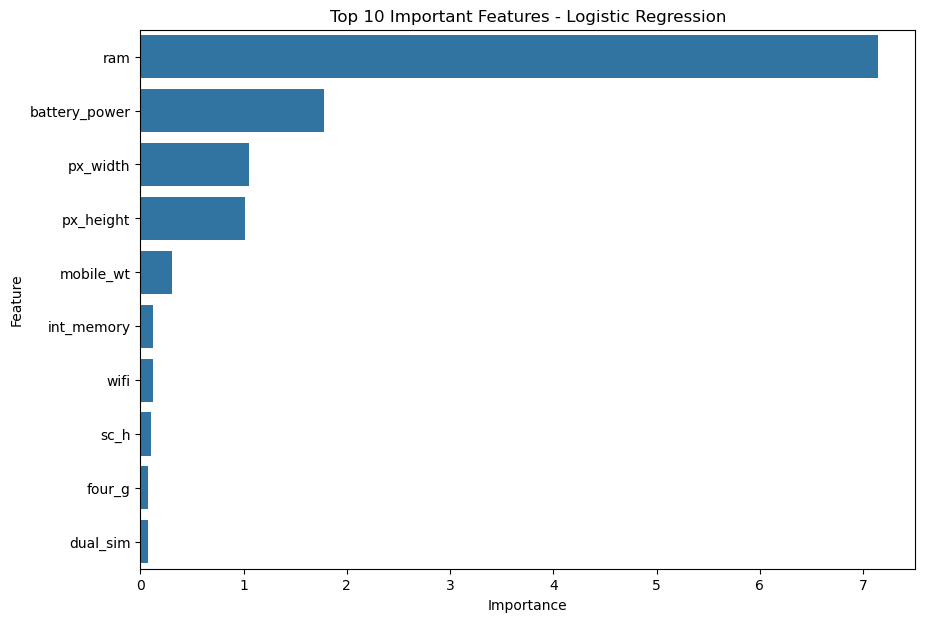

In [44]:
plt.figure(figsize=(10, 7))

sns.barplot(
    data=feature_importance.head(10),
    x='Importance',
    y='Feature'
)

plt.title('Top 10 Important Features - Logistic Regression')
plt.xlabel('Importance')
plt.ylabel('Feature')

plt.show()

## Feature Importance Analysis

The feature importance analysis of the Logistic Regression model shows that RAM is the most influential feature for predicting mobile phone price range, with an importance score of approximately 7.15.

Battery power is the second most influential feature, followed by pixel width and pixel height. The remaining features have considerably smaller importance scores.

These results are consistent with the EDA, where RAM showed a very strong positive correlation with price range. Therefore, RAM appears to be the most important specification for distinguishing between different mobile phone price categories in this dataset.

In [45]:
X.columns.tolist()

['battery_power',
 'blue',
 'clock_speed',
 'dual_sim',
 'fc',
 'four_g',
 'int_memory',
 'm_dep',
 'mobile_wt',
 'n_cores',
 'pc',
 'px_height',
 'px_width',
 'ram',
 'sc_h',
 'sc_w',
 'talk_time',
 'three_g',
 'touch_screen',
 'wifi']

In [46]:
# sample mobile

new_mobile = pd.DataFrame([{
    'battery_power': 1500,
    'blue': 1,
    'clock_speed': 2.0,
    'dual_sim': 1,
    'fc': 8,
    'four_g': 1,
    'int_memory': 32,
    'm_dep': 0.5,
    'mobile_wt': 140,
    'n_cores': 8,
    'pc': 12,
    'px_height': 900,
    'px_width': 1600,
    'ram': 3000,
    'sc_h': 15,
    'sc_w': 7,
    'talk_time': 15,
    'three_g': 1,
    'touch_screen': 1,
    'wifi': 1
}])

In [47]:
new_mobile_scaled = scaler.transform(new_mobile)

In [49]:
prediction = lr_model.predict(new_mobile_scaled)
print("Predicted Price Range:", prediction[0])

Predicted Price Range: 3


In [50]:
price_labels = {
    0: "Low Cost",
    1: "Medium Cost",
    2: "High Cost",
    3: "Very High Cost"
}
print("Predicted Price Category:", price_labels[prediction[0]])

Predicted Price Category: Very High Cost


## Prediction on New Mobile Phone

A new mobile phone specification was provided to the trained Logistic Regression model. After applying the same feature scaling used during training, the model predicted the phone's price range as **3 (Very High Cost)**.

This demonstrates that the trained model can classify a new mobile phone into one of the four predefined price categories based on its specifications.

In [51]:
import pickle

with open('cellphone_price_model.pkl', 'wb') as file:
    pickle.dump(lr_model, file)

with open('cellphone_scaler.pkl', 'wb') as file:
    pickle.dump(scaler, file)

print("Model and scaler saved successfully.")

Model and scaler saved successfully.


In [52]:
with open('cellphone_price_model.pkl', 'rb') as file:
    loaded_model = pickle.load(file)

with open('cellphone_scaler.pkl', 'rb') as file:
    loaded_scaler = pickle.load(file)

print("Model and scaler loaded successfully.")

Model and scaler loaded successfully.


In [53]:
loaded_prediction = loaded_model.predict(
    loaded_scaler.transform(new_mobile)
)
print("Prediction from loaded model:", loaded_prediction[0])
print("Predicted Price Category:", price_labels[loaded_prediction[0]])

Prediction from loaded model: 3
Predicted Price Category: Very High Cost


## Model Comparison Report

Five classification models were trained and evaluated for predicting the cellphone price range: Logistic Regression, K-Nearest Neighbors (KNN), Decision Tree, Random Forest, and Support Vector Machine (SVM).

| Model | Accuracy | Macro F1-Score |
|---|---:|---:|
| Logistic Regression | 96.5% | 0.96 |
| SVM | 89.5% | 0.90 |
| Random Forest | 88.0% | 0.88 |
| Decision Tree | 83.0% | 0.83 |
| KNN | 50.0% | 0.51 |

Logistic Regression achieved the highest performance with an accuracy of 96.5% and a macro F1-score of 0.96. It also performed consistently well across all four price categories.

SVM was the second-best model, followed by Random Forest, Decision Tree, and KNN. KNN showed the weakest performance with an accuracy of only 50%.

### Best Model for Production

Logistic Regression is selected as the best model for production because it achieved the highest accuracy and macro F1-score. It provides reliable and balanced classification across all four price ranges and is also computationally efficient, making it suitable for deployment.

## Report on Challenges Faced

### 1. Different Feature Scales
The dataset contained features with different numerical ranges. For example, RAM had values up to 3998, while mobile depth ranged only from 0.1 to 1.0.

**Technique Used:** StandardScaler was applied to the training and testing features for Logistic Regression, KNN, and SVM.

**Reason:** Scaling prevents features with larger numerical values from dominating the models, especially distance-based and scale-sensitive algorithms.

### 2. Different Model Performance
The classification models produced significantly different results. KNN achieved only 50% accuracy, while Logistic Regression achieved 96.5%.

**Technique Used:** Multiple classification algorithms were trained and evaluated using accuracy, precision, recall, and F1-score.

**Reason:** Comparing multiple models helps identify the algorithm that is most suitable for the dataset.

### 3. Difficulty in Distinguishing Middle Price Ranges
Some models had more difficulty distinguishing Price Ranges 1 and 2 compared with Price Ranges 0 and 3.

**Technique Used:** Classification reports and confusion matrices were used to analyze class-wise performance.

**Reason:** These evaluation techniques help identify which price categories are more difficult for the models to classify.

### 4. Feature Selection and Interpretation
The dataset contained 20 input features, and their influence on price range varied considerably.

**Technique Used:** Correlation analysis and Logistic Regression feature importance were performed.

**Reason:** This helped identify the most influential features. RAM was found to be the strongest feature for predicting price range.
